# Strategy Grid

This notebook builds the backtesting framework and runs a large grid of strategy variants on the in-sample data. Each strategy is defined by the positions it holds each day, and every variant is run through the same backtest so that results can be compared fairly against a buy-and-hold benchmark.

Positions are decided at each day's close and held from the next day on, so no strategy uses information that would not have been available at the time. The out-of-sample data is not used in this notebook.

In [18]:
# Importing the necessary packages and functions
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from functions import get_data

## Data

In-sample price data (2006–2020) is downloaded for each asset, and daily close-to-close returns are calculated for use in every backtest.

In [40]:
# Getting the required data
ticker, start_date, end_date = 'SPY', '2006-01-01', '2021-01-01'
SPY_data = get_data(ticker, start_date, end_date)

# Function to calculate the close-to-close returns for a ticker
def daily_returns(ticker_data):
    current = ticker_data['Close']
    previous = current.shift(1)                  # yesterday's close lined up with today's
    returns = (current - previous) / previous    # % change from yesterday to today
    returns = returns.fillna(0)                  # first day has no previous close
    return returns

[*********************100%***********************]  1 of 1 completed


## Backtest Functions

Each strategy outputs the position it holds each day. These functions turn positions into daily returns and cumulative growth. Positions are shifted forward one day so trades are based only on information available at the previous close.

In [42]:
# Function to calculate a strategy's daily returns
def strategy_returns(positions, asset_returns, cost=0.0):
    position = positions.shift(1).fillna(0)              # today you hold what you decided at yesterday's close
    previous_position = position.shift(1).fillna(0)      # what you held the day before
    trade_size = (position - previous_position).abs()    # how much you bought or sold to get to today's position
    gross_returns = position * asset_returns             # return earned on the position held
    trading_costs = cost * trade_size                    # cost paid on the amount traded
    net_returns = gross_returns - trading_costs   
    return net_returns

# Function to calculate cumulative % growth
def cumulative_return(returns):
    daily_growth = 1 + returns                         # e.g. a +2% day becomes 1.02
    cumulative_growth = daily_growth.cumprod()         # value of $1 invested at the start
    percent_return = 100 * (cumulative_growth - 1)     # convert to % gain
    return percent_return

## Performance Metrics

Each strategy is evaluated on annualized return, annualized volatility, Sharpe ratio, and maximum drawdown. All annualized figures assume 252 trading days per year, and the Sharpe ratio assumes a risk-free rate of zero.

In [45]:
# Function to calculate annualized return
def annualized_return(returns):
    total_growth = (1 + returns).prod()                # final value of $1
    years = (len(returns) - 1) / 252                   # 252 trading days in a year
    ann_return = total_growth ** (1 / years) - 1
    return ann_return

# Function to calculate annualized volatility
def annualized_volatility(returns):
    daily_volatility = returns.std()
    ann_vol = daily_volatility * np.sqrt(252)
    return ann_vol

# Function to calculate the Sharpe ratio
def sharpe_ratio(returns):
    annual_mean = returns.mean() * 252
    annual_volatility = annualized_volatility(returns)
    if annual_volatility == 0:                            # no movement in the strategy
        return 0.0
    sharpe = annual_mean / annual_volatility
    return sharpe

# Function to calculate maximum drawdown
def max_drawdown(returns):
    cumulative_growth = (1 + returns).cumprod()
    running_peak = cumulative_growth.cummax()             # highest value reached up to each day
    drawdown = cumulative_growth / running_peak - 1       # % below that peak
    worst_drawdown = drawdown.min()                       # most negative = worst drawdown
    return worst_drawdown

# Function to calculate all performance metrics at once
def performance_metrics(returns):
    ann_return = annualized_return(returns)
    ann_vol = annualized_volatility(returns)
    sharpe = sharpe_ratio(returns)
    worst_drawdown = max_drawdown(returns)
    return ann_return, ann_vol, sharpe, worst_drawdown

# Function to summarize all metrics for one strategy
def summary(returns):
    return {'Ann. Return': annualized_return(returns), 
            'Ann. Volatility': annualized_volatility(returns), 
            'Sharpe': sharpe_ratio(returns), 
            'Max Drawdown': max_drawdown(returns)}

## Buy-and-Hold Benchmark

Buy-and-hold holds a position of 1 every day and is the benchmark every strategy variant is compared against. Its cumulative return is also checked against the return calculated directly from prices to confirm the backtest functions work correctly.

In [48]:
# Running the buy-and-hold strategy
SPY_returns = daily_returns(SPY_data)
SPY_bh_positions = pd.Series(1.0, index=SPY_data.index)
SPY_bh_returns = strategy_returns(bh_positions, SPY_returns)

# Checking the backtest against the return calculated directly from prices
from_backtest = cumulative_return(bh_returns).iloc[-1]
from_prices = 100 * (SPY_data['Close'].iloc[-1] / SPY_data['Close'].iloc[0] - 1)
print(f'From backtest: {from_backtest:.4f}%')
print(f'From prices:   {from_prices:.4f}%')

# Buy-and-hold performance
pd.Series(summary(bh_returns)).round(4)

From backtest: 299.0339%
From prices:   299.0339%


Ann. Return        0.0968
Ann. Volatility    0.2008
Sharpe             0.5605
Max Drawdown      -0.5519
dtype: float64

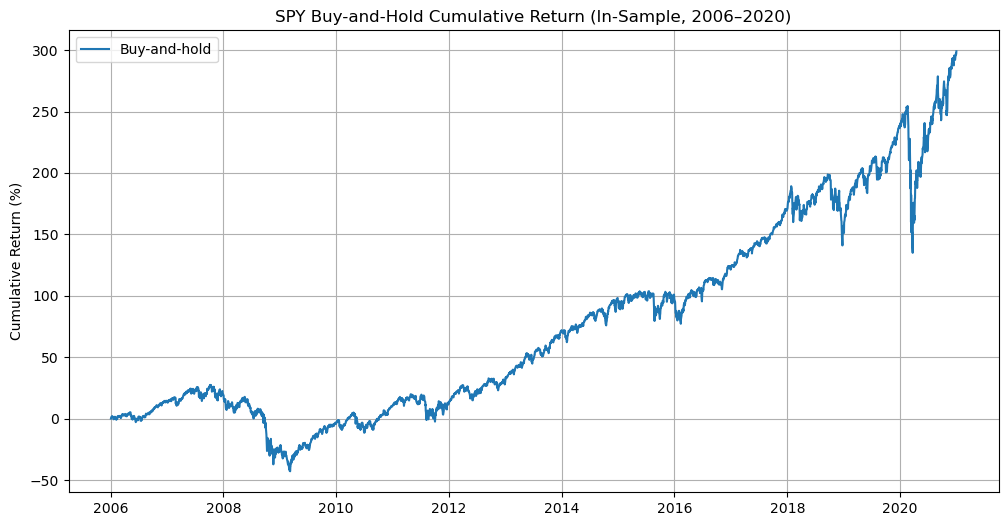

In [34]:
# Plotting buy-and-hold cumulative return
plt.figure(figsize=(12, 6))
plt.plot(cumulative_return(bh_returns), label='Buy-and-hold')
plt.title(f'{ticker} Buy-and-Hold Cumulative Return (In-Sample, 2006–2020)')
plt.ylabel('Cumulative Return (%)')
plt.legend()
plt.grid(True)
plt.show()

## Strategy Grid